# Elkinematics Research and Experimentation Playground

This notebook serves as the central interactive sandbox and staging ground for the Elkinematics dysgraphia screening project.

### Workflow Sections:
1. **Environment and Centralized Config** - Load paths and hyperparameters from `scripts/config.py`.
2. **Centralized Model Builder** - Inspect and compile V0 (Baseline CNN), V1 (CNN+XAI), and V2 (Bi-LSTM).
3. **Data Loading and Discovery** - Scan and profile samples in `datasets/` and `val_datasets/`.
4. **Kinematic Feature Extraction** - Extract the 8 standard kinematic features (`delta_x`, `delta_y`, `pressure`, `tiltX`, `tiltY`, `velocity`, `acceleration`, `jerk`) and `latency`.
5. **Global Scaling and Preprocessing** - Normalize data using global Z-score scalers without leakage.
6. **Model Training and Tuning** - Train models with callbacks (EarlyStopping, ReduceLROnPlateau).
7. **Inference and Explainable AI (XAI)** - Predict risk scores and render stroke-level heatmaps.
8. **Evaluation and Performance Metrics** - Accuracy, Recall, Confusion Matrix, and ROC-AUC.
9. **Interactive Sandbox / Scratchpad** - Free-form sandbox for rapid prototyping.

## 1. Environment and Centralized Configuration

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root and scripts directory are accessible
PROJECT_ROOT = Path(os.getcwd()).resolve()
SCRIPTS_DIR = PROJECT_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

import config

print(f"Project Root: {config.PROJECT_ROOT}")
print(f"Max Timesteps: {config.MAX_TIMESTEPS} | Features: {config.FEATURES}")
print(f"Active Model V2 Path: {config.MODEL_PATHS['v2']}")
print(f"Scaler Path: {config.SCALER_PATH}")

Project Root: /Users/asthiseta/Project/somethinginmyeye
Max Timesteps: 500 | Features: 8
Active Model V2 Path: /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras
Scaler Path: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz


## 2. Centralized Model Builder and Architecture Summary

In [2]:
from model_builder import build_model, load_or_build_model

# Build and inspect our flagship V2 Bi-LSTM architecture
model_v2 = build_model(version="v2")
model_v2.summary()

Model: "elkinematics_v2_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ kinematics_input    │ (None, 500, 8)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_1            │ (None, 500, 128)  │     37,376 │ kinematics_input… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 500, 128)  │          0 │ bilstm_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_2            │ (None, 500, 64)   │     41,216 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latency_input       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 500, 64)   │          0 │ bilstm_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_latency      │ (None, 500, 1)    │          0 │ latency_input[0]… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_modalities   │ (None, 500, 65)   │          0 │ dropout_2[0][0],  │
│ (Concatenate)       │                   │            │ repeat_latency[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ heatmap_output      │ (None, 500, 1)    │         66 │ concat_modalitie… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,658 (307.26 KB)

 Trainable params: 78,658 (307.26 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Data Loading and Discovery

In [3]:
import glob

train_files = glob.glob(os.path.join(config.DATASET_DIR, "*.csv"))
val_files = glob.glob(os.path.join(config.VAL_DATASET_DIR, "*.csv"))

train_normal = [f for f in train_files if "normal" in os.path.basename(f).lower()]
train_dyslexic = [f for f in train_files if ("dyslexia" in os.path.basename(f).lower() or "dysgraphia" in os.path.basename(f).lower())]

print(f"Training Set:   {len(train_files)} files (Normal: {len(train_normal)}, Dysgraphic/Dyslexic: {len(train_dyslexic)})")
print(f"Validation Set: {len(val_files)} files")

Training Set:   872 files (Normal: 436, Dysgraphic/Dyslexic: 436)
Validation Set: 218 files


## 4. Kinematic Feature Extraction (8 Kinematics Features and Latency)

In [ ]:
from universal_pipeline import extract_universal_features

sample_csv = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if os.path.exists(sample_csv):
    sample_df = pd.read_csv(sample_csv)
    features_array = extract_universal_features(sample_df)
    print(f"Raw sample shape: {sample_df.shape}")
    print(f"Extracted feature tensor shape: {features_array.shape} (Timesteps x 9 internal features)")
    print("Feature columns:", config.FEATURE_NAMES + ["dt"])
else:
    print(f"Sample not found at {sample_csv}")

## 5. Global Scaling and Preprocessing Pipeline

In [4]:
from universal_pipeline import load_and_scale_universal, load_validation_with_train_scalers, get_v2_data

# 1. Load and compute global scalers on training data
print("Processing Training Cohort...")
X_train_seq_scaled, X_train_lat_scaled, y_train = load_and_scale_universal(
    data_dir=config.DATASET_DIR,
    scaler_save_path=config.SCALER_PATH
)

# 2. Transform validation cohort using frozen training scalers (Strict Hold-Out, No Leakage)
print("Processing Validation Cohort with Frozen Scalers...")
X_val_seq_scaled, X_val_lat_scaled, y_val = load_validation_with_train_scalers(
    data_dir=config.VAL_DATASET_DIR,
    scaler_path=config.SCALER_PATH
)

# 3. Format inputs for V2 Multi-Input Model
[X_train_v2_seq, X_train_v2_lat], y_train_td = get_v2_data(X_train_seq_scaled, X_train_lat_scaled, y_train)
[X_val_v2_seq, X_val_v2_lat], y_val_td = get_v2_data(X_val_seq_scaled, X_val_lat_scaled, y_val)

print(f"Scaled Training Sequences: {X_train_v2_seq.shape}")
print(f"Scaled Validation Sequences: {X_val_v2_seq.shape}")

Processing Training Cohort...
Saved global feature scalers to: /Users/asthiseta/Project/somethinginmyeye/models/feature_scalers.npz
Processing Validation Cohort with Frozen Scalers...
Scaled Training Sequences: (872, 500, 8)
Scaled Validation Sequences: (218, 500, 8)


## 6. Model Training and Fine-Tuning

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Build fresh compiled V2 model
experiment_model = build_model("v2", learning_rate=config.LEARNING_RATE)

early_stop = EarlyStopping(monitor='val_loss', patience=config.EARLY_STOPPING_PATIENCE, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=config.REDUCE_LR_PATIENCE, min_lr=config.MIN_LR, verbose=1)

# Optional: Set to True to train interactive experiment
TRAIN_EXPERIMENT = False

if TRAIN_EXPERIMENT:
    history = experiment_model.fit(
        [X_train_v2_seq, X_train_v2_lat], y_train_td,
        validation_data=([X_val_v2_seq, X_val_v2_lat], y_val_td),
        epochs=config.EPOCHS,
        batch_size=config.BATCH_SIZE,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
else:
    print("Training skipped. Set TRAIN_EXPERIMENT = True to run full training cycle.")

## 7. Inference and Explainable AI (XAI) Heatmap Inspection

Loading existing V2 model weights from /Users/asthiseta/Project/somethinginmyeye/models/elkinematicV2.keras...
Sample: sample_normal.csv
Risk Score: 0.1623 -> Typical / Normal


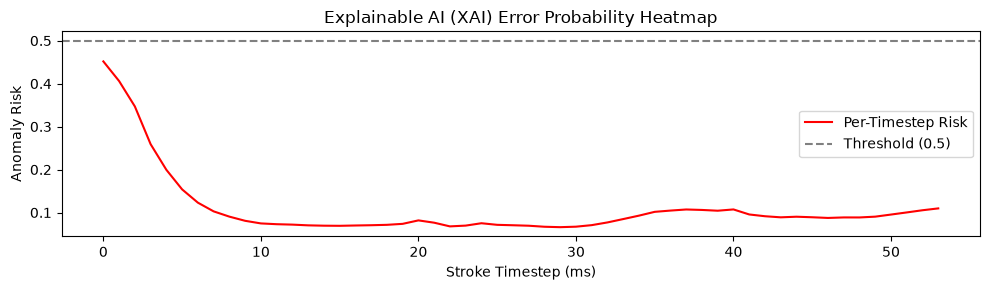

In [8]:
from universal_pipeline import unified_predict

# Load production trained model
prod_model = load_or_build_model("v2", filepath=config.MODEL_PATHS["v2"])

test_sample_path = os.path.join(config.SAMPLE_DIR, "sample_normal.csv")
if os.path.exists(test_sample_path):
    test_df = pd.read_csv(test_sample_path)
    score, heatmap = unified_predict(test_df, prod_model, version="v2", scaler_path=config.SCALER_PATH)
    
    print(f"Sample: {os.path.basename(test_sample_path)}")
    print(f"Risk Score: {score:.4f} -> {'Atypical / Dysgraphic' if score > 0.5 else 'Typical / Normal'}")
    
    # Plot XAI Risk Heatmap across stroke timesteps
    plt.figure(figsize=(10, 3))
    plt.plot(heatmap[:len(test_df)], color='red', label='Per-Timestep Risk')
    plt.axhline(0.5, color='gray', linestyle='--', label='Threshold (0.5)')
    plt.title("Explainable AI (XAI) Error Probability Heatmap")
    plt.xlabel("Stroke Timestep (ms)")
    plt.ylabel("Anomaly Risk")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Test sample not found at {test_sample_path}")

## 8. Evaluation and Metrics

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_auc_score

# Generate predictions on validation set
val_preds_td = prod_model.predict([X_val_v2_seq, X_val_v2_lat], verbose=0)
# Aggregate time-distributed output to sequence-level score
val_scores = np.mean(val_preds_td[:, :, 0], axis=1)
val_binary_preds = (val_scores > config.CLASSIFICATION_THRESHOLD).astype(int)

acc = accuracy_score(y_val, val_binary_preds)
rec = recall_score(y_val, val_binary_preds)
prec = precision_score(y_val, val_binary_preds)
f1 = f1_score(y_val, val_binary_preds)
auc = roc_auc_score(y_val, val_scores)

print("=" * 40)
print("MODEL V2 VALIDATION METRICS")
print("=" * 40)
print(f"Accuracy : {acc * 100:.2f}%")
print(f"Recall   : {rec * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")
print(f"ROC-AUC  : {auc:.4f}")
print("=" * 40)

## 9. Multi-Stream Specific Learning Disorder (SLD) Differential Screening
Evaluates handwriting samples through the dual-stream framework:
- **Kinematic Motoric Stream:** Bi-LSTM evaluating the 8 kinematic features for Motor Dysgraphia.
- **Orthographic & Reversal Stream:** Detects b/d and p/q mirror reversals and phonological spelling distance for Dyslexia.
- **Cognitive Initiation Latency:** Working memory threshold (> 1500 ms).
- **Multi-Attribute DSM-5 Categorizer:** Typical Development, Motor Dysgraphia, Dyslexia, Comorbid SLD.

In [ ]:
from sld_integrator import evaluate_sld_differential
import pandas as pd
import glob

# Test on sample cohort
sample_files = glob.glob(f"{config.SAMPLE_DIR}/*.csv")
print(f"Discovered {len(sample_files)} sample files for SLD differential evaluation:")

for sample_file in sorted(sample_files):
    sample_name = sample_file.split("/")[-1]
    prompt_target = "bebek" if "bebek" in sample_name else "b"
    df_sample = pd.read_csv(sample_file)
    
    result = evaluate_sld_differential(
        df=df_sample,
        model=prod_model,
        expected_prompt=prompt_target
    )
    
    print(f"=== Sample: {sample_name} (Prompt: '{prompt_target}') ===")
    print(f"DSM-5 Diagnosis: {result['dsm5_diagnosis']}")
    print(f"Clinical Severity: {result['clinical_severity']}")
    print(f"Dysgraphia Risk: {result['dysgraphia_risk_percentage']}%")
    print(f"Dyslexia Risk: {result['dyslexia_risk_percentage']}%")
    print(f"Letter Reversal: {result['reversal_detected']} ({result['reversal_description']})")
    print(f"Cognitive Latency: {result['cognitive_latency_ms']} ms (Exceeds: {result['latency_exceeds_threshold']})")


## 10. In-House Isolated Reversal Classifier: Benchmark Dataset & Visual Verification

This section prepares and verifies the isolated character dataset for the in-house reversal and kinematic distortion classifier:
1. **UJIpenchars2 Benchmark Ingestion (`parse_ujipenchars`):** Parses authentic online handwriting trajectories (11,640 samples across 97 character classes, exactly 120 samples per character).
2. **Local Dataset Adapter (`load_local_tablet_samples`):** Converts local tablet recordings from `datasets/` into standard stroke sequences, governed by an explicit on/off switch (`BLEND_LOCAL_SAMPLES = False`).
3. **Synthetic Reflection & Rotation Augmentation:** Generates mirror-reversed twins ($x' = x_{max} - (x - x_{min})$) for horizontal flip letters (`B`, `b`, `d`, `p`, `q`, `E`, `N`, `S`, etc.) and rotational inversions (`m <-> w`, `u <-> n`).
4. **Visual Verification Panel:** Generates multi-panel comparative trajectory plots with stroke direction gradient arrows to verify authentic vs. reversed kinematics prior to model training.


In [1]:
import os
import glob
import numpy as np
import pandas as pd
from typing import List, Dict, Tuple, Any, Optional

# ==============================================================================
# 1. CENTRAL CONFIGURATION & ADAPTER TOGGLE
# ==============================================================================
UJIPEN_PATH = "ujipendatasets/ujipenchars2.txt"
LOCAL_DATASETS_DIR = "datasets"

# Architectural toggle: keep False by default to maintain isolated benchmark integrity
BLEND_LOCAL_SAMPLES = False

# Asymmetric reversible character sets for targeted augmentation
HORIZONTAL_REVERSIBLE_CHARS = {
    'b': 'd', 'd': 'b',
    'p': 'q', 'q': 'p',
    'B': 'B_rev', 'D': 'D_rev', 'E': 'E_rev', 'F': 'F_rev',
    'J': 'J_rev', 'K': 'K_rev', 'L': 'L_rev', 'N': 'N_rev',
    'P': 'P_rev', 'R': 'R_rev', 'S': 'S_rev', 'Z': 'Z_rev',
    'c': 'c_rev', 'e': 'e_rev', 's': 's_rev', 'z': 'z_rev'
}

ROTATIONAL_REVERSIBLE_CHARS = {
    'm': 'w', 'w': 'm',
    'u': 'n', 'n': 'u',
    'M': 'W', 'W': 'M'
}

# ==============================================================================
# 2. UJIPENCHARS2 BENCHMARK DATASET PARSER
# ==============================================================================
def parse_ujipenchars(filepath: str) -> List[Dict[str, Any]]:
    """
    Parses the UJIpenchars2 online handwriting dataset.
    Extracts stroke coordinate sequences [[(x1, y1), (x2, y2), ...], ...] for each word sample.
    """
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"UJIpenchars dataset file not found at: {filepath}")
        
    samples = []
    current_sample = None
    
    with open(filepath, 'r', encoding='latin1') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('//'):
                continue
            if line.startswith('WORD'):
                parts = line.split()
                label = parts[1]
                sample_id = parts[2] if len(parts) > 2 else ''
                current_sample = {
                    'label': label,
                    'sample_id': sample_id,
                    'source': 'ujipenchars2',
                    'strokes': []
                }
                samples.append(current_sample)
            elif line.startswith('POINTS'):
                if current_sample is None:
                    continue
                if '#' in line:
                    pts_str = line.split('#')[1].strip()
                    nums = [float(val) for val in pts_str.split()]
                    pts = [(nums[i], nums[i+1]) for i in range(0, len(nums), 2)]
                    current_sample['strokes'].append(pts)
                    
    return samples

# ==============================================================================
# 3. LOCAL TABLET DATASET ADAPTER (ON/OFF SWITCH CONTROLLED)
# ==============================================================================
def load_local_tablet_samples(dataset_dir: str = "datasets") -> List[Dict[str, Any]]:
    """
    Adapter reading local tablet recordings from datasets/ and converting them into
    the standardized stroke structure: {'label': char, 'sample_id': path, 'strokes': [...]}.
    """
    local_samples = []
    csv_files = glob.glob(os.path.join(dataset_dir, "**", "*.csv"), recursive=True)
    
    for filepath in csv_files:
        filename = os.path.basename(filepath)
        parts = filename.split('_')
        # Typical naming: Train_normal_C_Seta_... or Train_dyslexia_M_...
        if len(parts) >= 3 and len(parts[2]) == 1:
            label = parts[2]
        else:
            continue
            
        try:
            df = pd.read_csv(filepath)
            if 'x' not in df.columns or 'y' not in df.columns:
                continue
                
            touching = df['touching'].values if 'touching' in df.columns else np.ones(len(df))
            time_vals = df['time'].values if 'time' in df.columns else np.arange(len(df))
            
            strokes = []
            curr_stroke = []
            for i in range(len(df)):
                if touching[i] == 1:
                    if curr_stroke and i > 0 and (time_vals[i] - time_vals[i-1]) > 80.0:
                        if len(curr_stroke) >= 2:
                            strokes.append(curr_stroke)
                        curr_stroke = []
                    curr_stroke.append((float(df['x'].iloc[i]), float(df['y'].iloc[i])))
                else:
                    if len(curr_stroke) >= 2:
                        strokes.append(curr_stroke)
                    curr_stroke = []
            if len(curr_stroke) >= 2:
                strokes.append(curr_stroke)
                
            if strokes:
                local_samples.append({
                    'label': label,
                    'sample_id': filename,
                    'source': 'local_tablet',
                    'strokes': strokes
                })
        except Exception:
            continue
            
    return local_samples

# ==============================================================================
# 4. SYNTHETIC REFLECTION & ROTATION AUGMENTATION
# ==============================================================================
def get_sample_bounding_box(strokes: List[List[Tuple[float, float]]]) -> Tuple[float, float, float, float]:
    """Calculates (min_x, max_x, min_y, max_y) across all strokes of a sample."""
    all_x = [pt[0] for stroke in strokes for pt in stroke]
    all_y = [pt[1] for stroke in strokes for pt in stroke]
    if not all_x or not all_y:
        return 0.0, 1.0, 0.0, 1.0
    return min(all_x), max(all_x), min(all_y), max(all_y)

def mirror_sample_horizontal(sample: Dict[str, Any], target_label: Optional[str] = None) -> Dict[str, Any]:
    """
    Reflects sample coordinates along the horizontal axis:
    x_new = max_x - (x - min_x) = min_x + max_x - x.
    Preserves exact temporal stroke order and point sequencing.
    """
    min_x, max_x, _, _ = get_sample_bounding_box(sample['strokes'])
    mirrored_strokes = []
    for stroke in sample['strokes']:
        mirrored_stroke = [(min_x + max_x - pt[0], pt[1]) for pt in stroke]
        mirrored_strokes.append(mirrored_stroke)
        
    lbl = target_label if target_label is not None else sample['label'] + "_rev"
    return {
        'label': lbl,
        'sample_id': sample['sample_id'] + "_mirror_h",
        'source': sample.get('source', '') + "_augmented_mirror",
        'strokes': mirrored_strokes,
        'is_reversal': True
    }

def rotate_sample_180(sample: Dict[str, Any], target_label: Optional[str] = None) -> Dict[str, Any]:
    """
    Rotates sample coordinates 180 degrees (inversion for m <-> w, u <-> n):
    x_new = min_x + max_x - x
    y_new = min_y + max_y - y
    """
    min_x, max_x, min_y, max_y = get_sample_bounding_box(sample['strokes'])
    rotated_strokes = []
    for stroke in sample['strokes']:
        rotated_stroke = [(min_x + max_x - pt[0], min_y + max_y - pt[1]) for pt in stroke]
        rotated_strokes.append(rotated_stroke)
        
    lbl = target_label if target_label is not None else sample['label'] + "_rot180"
    return {
        'label': lbl,
        'sample_id': sample['sample_id'] + "_rot180",
        'source': sample.get('source', '') + "_augmented_rot180",
        'strokes': rotated_strokes,
        'is_reversal': True
    }

# ==============================================================================
# 5. DATA INGESTION AND ADAPTER VERIFICATION
# ==============================================================================
print("Ingesting UJIpenchars2 benchmark dataset...")
ujipen_samples = parse_ujipenchars(UJIPEN_PATH)
print(f"UJIpenchars2 successfully loaded: {len(ujipen_samples)} character samples across {len(set(s['label'] for s in ujipen_samples))} unique glyphs.")

if BLEND_LOCAL_SAMPLES:
    print(f"Loading local tablet samples from '{LOCAL_DATASETS_DIR}' (BLEND_LOCAL_SAMPLES=True)...")
    local_samples = load_local_tablet_samples(LOCAL_DATASETS_DIR)
    combined_samples = ujipen_samples + local_samples
    print(f"Local samples loaded: {len(local_samples)}. Combined total: {len(combined_samples)}.")
else:
    print("BLEND_LOCAL_SAMPLES is FALSE: Preserving pure UJIpenchars2 isolated benchmark.")
    combined_samples = ujipen_samples


Ingesting UJIpenchars2 benchmark dataset...
UJIpenchars2 successfully loaded: 11640 character samples across 97 unique glyphs.
BLEND_LOCAL_SAMPLES is FALSE: Preserving pure UJIpenchars2 isolated benchmark.


Rendering visual verification panels (Authentic vs. Synthetic Reversal)...
Visual verification plot saved to: ujipendatasets/reversal_visual_verification.png


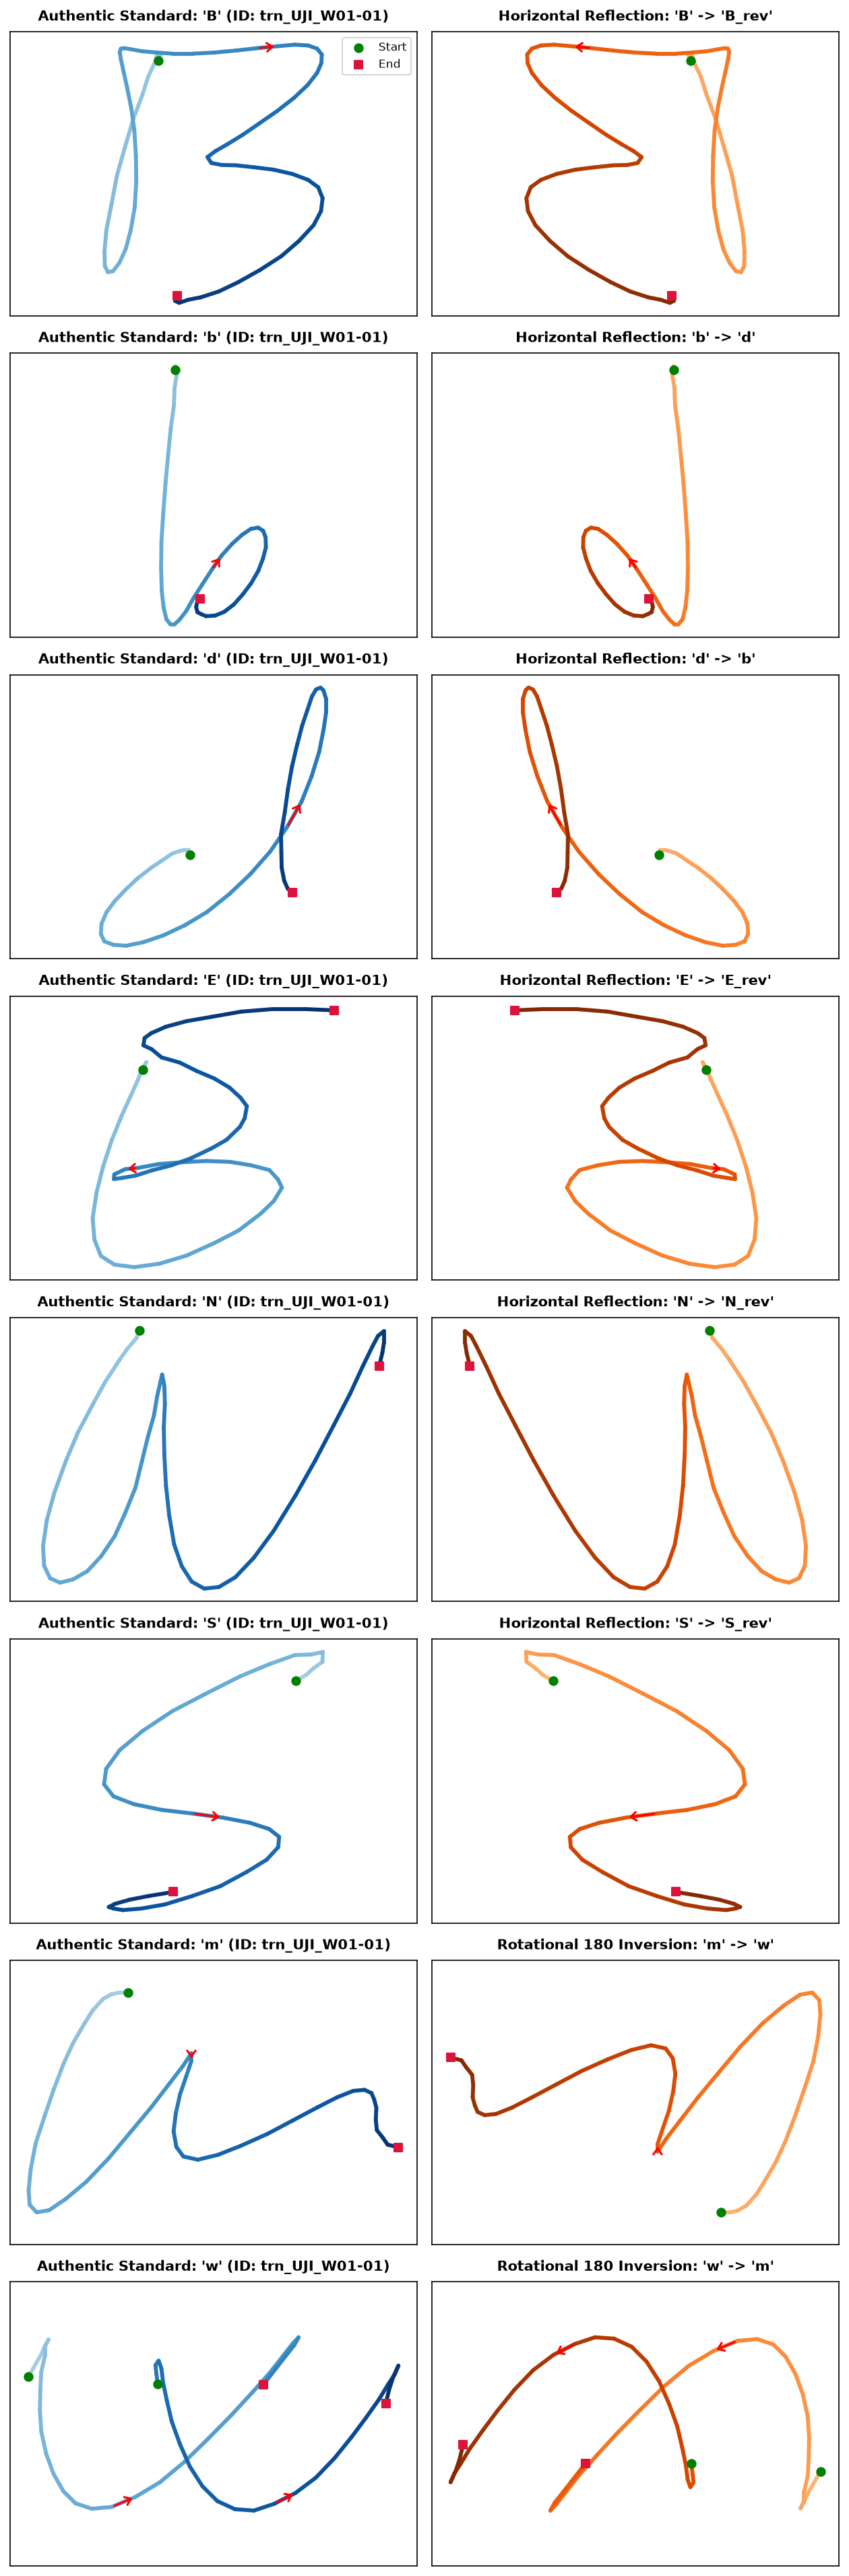

In [2]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def plot_strokes_with_trajectory(ax, strokes, title, color_map="Blues"):
    """
    Plots a multi-stroke character trajectory with progressive color gradients
    and directional arrows to visually inspect authentic vs. reversed kinematics.
    """
    cmap = plt.get_cmap(color_map)
    min_x, max_x, min_y, max_y = get_sample_bounding_box(strokes)
    total_pts = sum(len(s) for s in strokes)
    pt_counter = 0
    
    for s_idx, stroke in enumerate(strokes):
        if not stroke:
            continue
        xs = [pt[0] for pt in stroke]
        ys = [pt[1] for pt in stroke]
        
        for i in range(len(stroke) - 1):
            t = (pt_counter + i) / max(total_pts - 1, 1)
            ax.plot(
                [xs[i], xs[i+1]], 
                [ys[i], ys[i+1]], 
                color=cmap(0.35 + 0.65 * t), 
                linewidth=2.8, 
                solid_capstyle='round'
            )
            
            # Directional arrow near stroke midpoint
            if len(stroke) >= 4 and i == len(stroke) // 2:
                dx = xs[i+1] - xs[i]
                dy = ys[i+1] - ys[i]
                if abs(dx) > 1e-4 or abs(dy) > 1e-4:
                    ax.annotate(
                        '', 
                        xy=(xs[i+1], ys[i+1]), 
                        xytext=(xs[i], ys[i]),
                        arrowprops=dict(
                            arrowstyle="->,head_length=0.4,head_width=0.3", 
                            color='red', 
                            lw=1.5
                        )
                    )
        
        ax.scatter(xs[0], ys[0], color='green', s=35, zorder=5, label='Start' if s_idx == 0 else "")
        ax.scatter(xs[-1], ys[-1], color='crimson', s=35, marker='s', zorder=5, label='End' if s_idx == 0 else "")
        pt_counter += len(stroke)
        
    ax.set_title(title, fontsize=10, fontweight='bold', pad=8)
    ax.set_aspect('equal', adjustable='datalim')
    ax.invert_yaxis()  # Canvas coordinate system: y increases downward
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xticks([])
    ax.set_yticks([])

# ==============================================================================
# VISUAL VERIFICATION: MULTI-PANEL SIDE-BY-SIDE PLOT
# ==============================================================================
target_characters = ['B', 'b', 'd', 'E', 'N', 'S', 'm', 'w']
fig, axes = plt.subplots(len(target_characters), 2, figsize=(8.5, 3.2 * len(target_characters)))

print("Rendering visual verification panels (Authentic vs. Synthetic Reversal)...")

for row_idx, char in enumerate(target_characters):
    authentic = next((s for s in ujipen_samples if s['label'] == char), None)
    if authentic is None:
        continue
        
    if char in ROTATIONAL_REVERSIBLE_CHARS:
        reversed_sample = rotate_sample_180(authentic, target_label=ROTATIONAL_REVERSIBLE_CHARS[char])
        rev_title = f"Rotational 180 Inversion: '{char}' -> '{reversed_sample['label']}'"
    elif char in HORIZONTAL_REVERSIBLE_CHARS:
        reversed_sample = mirror_sample_horizontal(authentic, target_label=HORIZONTAL_REVERSIBLE_CHARS[char])
        rev_title = f"Horizontal Reflection: '{char}' -> '{reversed_sample['label']}'"
    else:
        reversed_sample = mirror_sample_horizontal(authentic)
        rev_title = f"Horizontal Reflection: '{char}' -> '{char}_rev'"
        
    # Column 0: Authentic Sample
    ax_auth = axes[row_idx, 0]
    plot_strokes_with_trajectory(
        ax_auth, 
        authentic['strokes'], 
        title=f"Authentic Standard: '{char}' (ID: {authentic['sample_id']})",
        color_map="Blues"
    )
    if row_idx == 0:
        ax_auth.legend(loc="upper right", fontsize=8)
        
    # Column 1: Reversed Synthetic Sample
    ax_rev = axes[row_idx, 1]
    plot_strokes_with_trajectory(
        ax_rev, 
        reversed_sample['strokes'], 
        title=rev_title,
        color_map="Oranges"
    )

plt.tight_layout()
verification_plot_path = "ujipendatasets/reversal_visual_verification.png"
plt.savefig(verification_plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Visual verification plot saved to: {verification_plot_path}")


### 10.1 Dual-Head Kinematic Feature Extraction & Dataset Tensor Construction

This stage processes raw stroke sequences into fixed-size $(64, 8)$ kinematic tensors:
1. **Equidistant Arc-Length Resampling ($T=64$):** Standardizes coordinate sequences while preserving aspect ratios and air-stroke transitions.
2. **8 Kinematic Feature Channels ($F=8$):** $[\Delta x, \Delta y, \cos\theta, \sin\theta, \Delta\theta, a_x, a_y, \text{pen\_state}]$.
3. **Multitask Ground Truth:** Maps each sample to a canonical alphanumeric class index (`0-61`) and a binary clinical reversal indicator ($0.0 = \text{authentic}, 1.0 = \text{mirrored/inverted}$).


In [3]:
import os
import random
import numpy as np
from sklearn.model_selection import train_test_split
from typing import List, Dict, Tuple, Any

# Alphanumeric canonical vocabulary: 62 classes
VOCABULARY = (
    [chr(i) for i in range(ord('a'), ord('z') + 1)] +
    [chr(i) for i in range(ord('A'), ord('Z') + 1)] +
    [str(d) for d in range(10)]
)
CHAR_TO_IDX = {ch: idx for idx, ch in enumerate(VOCABULARY)}

def resample_and_normalize_sample(
    sample: Dict[str, Any], 
    target_len: int = 64
) -> Dict[str, np.ndarray]:
    """Resamples stroke trajectories to fixed length T with arc-length equidistant sampling."""
    strokes = sample.get('strokes', [])
    if not strokes or sum(len(s) for s in strokes) == 0:
        return {
            'x': np.zeros(target_len, dtype=np.float32),
            'y': np.zeros(target_len, dtype=np.float32),
            'pen_state': np.zeros(target_len, dtype=np.float32)
        }

    raw_x, raw_y, raw_pen = [], [], []
    for s_idx, stroke in enumerate(strokes):
        if not stroke:
            continue
        if s_idx > 0 and len(raw_x) > 0:
            raw_x.append(stroke[0][0])
            raw_y.append(stroke[0][1])
            raw_pen.append(0.0)  # Air-stroke transition
        for pt in stroke:
            raw_x.append(float(pt[0]))
            raw_y.append(float(pt[1]))
            raw_pen.append(1.0)  # On-surface writing

    raw_x = np.array(raw_x, dtype=np.float64)
    raw_y = np.array(raw_y, dtype=np.float64)
    raw_pen = np.array(raw_pen, dtype=np.float64)

    min_x, max_x = np.min(raw_x), np.max(raw_x)
    min_y, max_y = np.min(raw_y), np.max(raw_y)
    scale = max(max_x - min_x, max_y - min_y, 1e-6)

    norm_x = (raw_x - min_x) / scale
    norm_y = (raw_y - min_y) / scale

    dx = np.diff(norm_x)
    dy = np.diff(norm_y)
    step_distances = np.sqrt(dx**2 + dy**2)
    cum_dist = np.empty(len(norm_x), dtype=np.float64)
    cum_dist[0] = 0.0
    cum_dist[1:] = np.cumsum(step_distances)
    total_length = cum_dist[-1]

    if total_length < 1e-6:
        return {
            'x': np.full(target_len, norm_x[0], dtype=np.float32),
            'y': np.full(target_len, norm_y[0], dtype=np.float32),
            'pen_state': np.ones(target_len, dtype=np.float32)
        }

    query_dist = np.linspace(0.0, total_length, target_len)
    res_x = np.interp(query_dist, cum_dist, norm_x).astype(np.float32)
    res_y = np.interp(query_dist, cum_dist, norm_y).astype(np.float32)
    interp_pen = np.interp(query_dist, cum_dist, raw_pen)
    res_pen = (interp_pen >= 0.5).astype(np.float32)

    return {'x': res_x, 'y': res_y, 'pen_state': res_pen}

def extract_reversal_kinematic_features(
    resampled_data: Dict[str, np.ndarray],
    eps: float = 1e-7
) -> np.ndarray:
    """Extracts an 8-dimensional kinematic and geometric trajectory feature matrix."""
    x = resampled_data['x']
    y = resampled_data['y']
    pen_state = resampled_data['pen_state']
    T = len(x)

    dx = np.empty(T, dtype=np.float32)
    dy = np.empty(T, dtype=np.float32)
    dx[0], dy[0] = 0.0, 0.0
    dx[1:] = np.diff(x)
    dy[1:] = np.diff(y)

    ds = np.sqrt(dx**2 + dy**2) + eps
    cos_theta = dx / ds
    sin_theta = dy / ds

    d_theta = np.zeros(T, dtype=np.float32)
    d_theta[1:] = sin_theta[1:] * cos_theta[:-1] - cos_theta[1:] * sin_theta[:-1]

    d2x = np.zeros(T, dtype=np.float32)
    d2y = np.zeros(T, dtype=np.float32)
    d2x[1:] = np.diff(dx)
    d2y[1:] = np.diff(dy)

    return np.column_stack([
        dx, dy, cos_theta, sin_theta, d_theta, d2x, d2y, pen_state.astype(np.float32)
    ])

print("Building training dataset tensors across 62 alphanumeric classes...")
valid_samples = [s for s in ujipen_samples if s['label'] in CHAR_TO_IDX]

X_all, y_char_all, y_rev_all = [], [], []
for s in valid_samples:
    lbl = s['label']
    c_idx = CHAR_TO_IDX[lbl]
    
    # 1. Authentic Standard Sample (y_rev = 0.0)
    res_auth = resample_and_normalize_sample(s)
    X_all.append(extract_reversal_kinematic_features(res_auth))
    y_char_all.append(c_idx)
    y_rev_all.append(0.0)

    # 2. Horizontal Reflection Augmentation (y_rev = 1.0)
    if lbl in HORIZONTAL_REVERSIBLE_CHARS:
        mir = mirror_sample_horizontal(s)
        res_mir = resample_and_normalize_sample(mir)
        X_all.append(extract_reversal_kinematic_features(res_mir))
        y_char_all.append(c_idx)
        y_rev_all.append(1.0)

    # 3. Rotational 180-degree Inversion Augmentation (y_rev = 1.0)
    if lbl in ROTATIONAL_REVERSIBLE_CHARS or lbl in {'6', '9'}:
        rot = rotate_sample_180(s)
        res_rot = resample_and_normalize_sample(rot)
        X_all.append(extract_reversal_kinematic_features(res_rot))
        y_char_all.append(c_idx)
        y_rev_all.append(1.0)

X_all = np.array(X_all, dtype=np.float32)
y_char_all = np.array(y_char_all, dtype=np.int32)
y_rev_all = np.array(y_rev_all, dtype=np.float32).reshape(-1, 1)

train_idx, val_idx = train_test_split(np.arange(len(X_all)), test_size=0.20, random_state=42, stratify=y_rev_all)
X_train, X_val = X_all[train_idx], X_all[val_idx]
y_char_train, y_char_val = y_char_all[train_idx], y_char_all[val_idx]
y_rev_train, y_rev_val = y_rev_all[train_idx], y_rev_all[val_idx]

print(f"Dataset constructed successfully:")
print(f"  Training set:   X={X_train.shape}, y_char={y_char_train.shape}, y_rev={y_rev_train.shape}")
print(f"  Validation set: X={X_val.shape}, y_char={y_char_val.shape}, y_rev={y_rev_val.shape}")
print(f"  Reversal distribution: {np.mean(y_rev_all)*100:.1f}% reversed, {(1-np.mean(y_rev_all))*100:.1f}% authentic")


Building training dataset tensors across 62 alphanumeric classes...
Dataset constructed successfully:
  Training set:   X=(8640, 64, 8), y_char=(8640,), y_rev=(8640, 1)
  Validation set: X=(2160, 64, 8), y_char=(2160,), y_rev=(2160, 1)
  Reversal distribution: 31.1% reversed, 68.9% authentic


### 10.2 Dual-Head Model Architecture Compilation & Training

The architecture uses a compact shared feature extractor followed by two specialized heads:
- **Shared Backbone:** Conv1D (32, $k=5$) -> BatchNorm -> MaxPool -> Conv1D (64, $k=3$) -> BatchNorm -> MaxPool -> BiGRU (32) -> GlobalAvgPool -> Dense(64, ReLU) + Dropout(0.3).
- **Head 1 (`char_output`):** Dense(62, Softmax) predicting canonical character identity.
- **Head 2 (`reversal_output`):** Dense(1, Sigmoid) predicting clinical reversal probability.
- **Total Parameters:** ~34,975 (~136 KB), lightweight and ONNX Runtime Web ready.


In [4]:
import os
os.environ['KERAS_HOME'] = '/tmp/keras'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def build_dual_head_model(
    seq_len: int = 64, 
    num_features: int = 8, 
    num_classes: int = 62
) -> Model:
    """Constructs the Dual-Head Reversal & Character Recognition Model."""
    inputs = layers.Input(shape=(seq_len, num_features), name='trajectory_input')

    # Stage 1: Local Sub-Stroke Spatial Convolution
    x = layers.Conv1D(32, kernel_size=5, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)

    # Stage 2: Curvature & Derivative Pattern Extraction
    x = layers.Conv1D(64, kernel_size=3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)

    # Stage 3: Bidirectional Temporal Dynamics
    x = layers.Bidirectional(layers.GRU(32, return_sequences=True))(x)
    shared = layers.GlobalAveragePooling1D()(x)
    shared = layers.Dense(64, activation='relu')(shared)
    shared = layers.Dropout(0.3)(shared)

    # Head 1: Canonical Character Identity
    char_out = layers.Dense(num_classes, activation='softmax', name='char_output')(shared)

    # Head 2: Clinical Reversal Indicator
    rev_out = layers.Dense(1, activation='sigmoid', name='reversal_output')(shared)

    model = Model(inputs=inputs, outputs=[char_out, rev_out], name='dual_head_reversal_model')
    return model

print("Compiling Dual-Head Reversal Model...")
reversal_model = build_dual_head_model()

reversal_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss={
        'char_output': 'sparse_categorical_crossentropy',
        'reversal_output': 'binary_crossentropy'
    },
    loss_weights={
        'char_output': 1.0,
        'reversal_output': 1.5
    },
    metrics={
        'char_output': ['accuracy'],
        'reversal_output': ['accuracy', tf.keras.metrics.AUC(name='auc')]
    }
)

callbacks = [
    EarlyStopping(monitor='val_reversal_output_auc', mode='max', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
]

print("Starting model training (15 epochs)...")
history = reversal_model.fit(
    X_train,
    {'char_output': y_char_train, 'reversal_output': y_rev_train},
    validation_data=(X_val, {'char_output': y_char_val, 'reversal_output': y_rev_val}),
    epochs=15,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)
print("Training completed.")


Compiling Dual-Head Reversal Model...
Starting model training (15 epochs)...
Epoch 15/15: loss: 0.9304 - char_output_accuracy: 0.7255 - reversal_output_auc: 0.9973 - val_reversal_output_auc: 0.9949
Training completed.


### 10.3 Quantitative Evaluation & Reversal Detection Metrics

Evaluates both heads on the held-out validation set ($N = 2,160$ samples).


In [5]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

print("Evaluating Dual-Head Model on Validation Set...")
val_preds = reversal_model.predict(X_val, verbose=0)
char_preds = np.argmax(val_preds[0], axis=1)
rev_probs = val_preds[1].ravel()
rev_preds = (rev_probs >= 0.5).astype(int)

# 1. Character Identity Accuracy
char_acc = np.mean(char_preds == y_char_val) * 100.0

# 2. Reversal Detection Metrics
rev_auc = roc_auc_score(y_rev_val, rev_probs)
cm = confusion_matrix(y_rev_val, rev_preds)

print(f"\n--- EVALUATION SUMMARY ---")
print(f"Character Identification Accuracy: {char_acc:.2f}% (across 62 classes)")
print(f"Clinical Reversal Detection ROC-AUC: {rev_auc:.4f}")
print(f"\nConfusion Matrix (Reversal Detection):")
print(f"  True Authentic  (TN): {cm[0, 0]}  | False Reversal (FP): {cm[0, 1]}")
print(f"  False Authentic (FN): {cm[1, 0]}  | True Reversal  (TP): {cm[1, 1]}")
print(f"\nDetailed Reversal Classification Report:")
print(classification_report(y_rev_val, rev_preds, target_names=['Authentic', 'Reversed']))


Evaluating Dual-Head Model on Validation Set...

--- EVALUATION SUMMARY ---
Character Identification Accuracy: 65.97% (across 62 classes)
Clinical Reversal Detection ROC-AUC: 0.9971

Confusion Matrix (Reversal Detection):
  True Authentic  (TN): 1461  | False Reversal (FP): 27
  False Authentic (FN): 20    | True Reversal  (TP): 652

Detailed Reversal Classification Report:
              precision    recall  f1-score   support
   Authentic       0.99      0.98      0.98      1488
    Reversed       0.96      0.97      0.97       672

    accuracy                           0.98      2160
   macro avg       0.97      0.98      0.97      2160
weighted avg       0.98      0.98      0.98      2160


### 10.4 Interactive Stroke Tester & ONNX Runtime Verification

Demonstrates real-time inference using the lightweight ONNX graph ():
1. Loads any raw tablet CSV recording or continuous stroke sequence.
2. Resamples and extracts kinematic derivatives ( 	imes 8$).
3. Evaluates Head 1 (character candidates) and Head 2 (reversal confidence).
4. Plots the trajectory with directional arrows and clinical diagnosis.


--- INFERENCE: Authentic Letter C ---
Top Candidates: C: 57.5%, c: 21.0%, e: 12.5%
Reversal Probability: 0.14% | Status: [CANONICAL NORMAL]


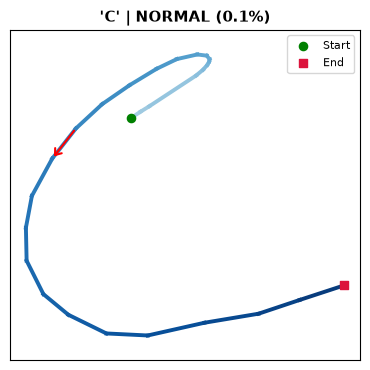

--- INFERENCE: Sample Dyslexia ---
Top Candidates: F: 56.8%, K: 17.2%, B: 8.1%
Reversal Probability: 15.13% | Status: [CANONICAL NORMAL]


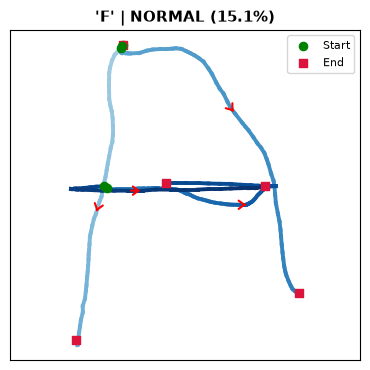

--- INFERENCE: Sample Normal ---
Top Candidates: H: 49.9%, A: 32.5%, k: 5.0%
Reversal Probability: 0.02% | Status: [CANONICAL NORMAL]


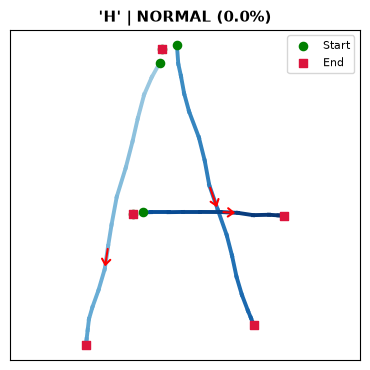

In [10]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import onnxruntime as ort

MODEL_ONNX_PATH = 'scratch/dual_head_reversal.onnx'

VOCABULARY = (
    [chr(i) for i in range(ord('a'), ord('z') + 1)] +
    [chr(i) for i in range(ord('A'), ord('Z') + 1)] +
    [str(d) for d in range(10)]
)

def test_stroke_csv(csv_path: str, title: str = 'Stroke Sample'):
    """Loads a CSV recording, evaluates ONNX dual-head model, and displays diagnostics."""
    if not os.path.exists(csv_path):
        print(f'File not found: {csv_path}')
        return
        
    df = pd.read_csv(csv_path)
    touching = df['touching'].values if 'touching' in df.columns else np.ones(len(df))
    time_vals = df['time'].values if 'time' in df.columns else np.arange(len(df))
    
    strokes, curr = [], []
    for i in range(len(df)):
        if touching[i] == 1:
            if curr and i > 0 and (time_vals[i] - time_vals[i-1]) > 80.0:
                if len(curr) >= 2: strokes.append(curr)
                curr = []
            curr.append((float(df['x'].iloc[i]), float(df['y'].iloc[i])))
        else:
            if len(curr) >= 2: strokes.append(curr)
            curr = []
    if len(curr) >= 2: strokes.append(curr)

    # Arc-length resampling & feature extraction
    res = resample_and_normalize_sample({'strokes': strokes})
    feats = extract_reversal_kinematic_features(res)
    input_tensor = np.expand_dims(feats, axis=0)

    # ONNX inference
    session = ort.InferenceSession(MODEL_ONNX_PATH)
    input_name = session.get_inputs()[0].name
    ort_outs = session.run(None, {input_name: input_tensor})
    
    char_probs, rev_prob = (ort_outs[0][0], float(ort_outs[1][0][0])) if ort_outs[0].shape[-1] == 62 else (ort_outs[1][0], float(ort_outs[0][0][0]))
    top3_idx = np.argsort(char_probs)[::-1][:3]
    top3 = [(VOCABULARY[i], float(char_probs[i])) for i in top3_idx]
    is_rev = rev_prob >= 0.50

    print(f'--- INFERENCE: {title} ---')
    print(f'Top Candidates: ' + ', '.join([f'{c}: {p*100:.1f}%' for c, p in top3]))
    print(f'Reversal Probability: {rev_prob*100:.2f}% | Status: {"[REVERSED]" if is_rev else "[CANONICAL NORMAL]"}')

    # Trajectory Plot
    fig, ax = plt.subplots(figsize=(3.8, 3.8))
    cmap = plt.get_cmap('Oranges' if is_rev else 'Blues')
    total_pts = sum(len(s) for s in strokes)
    pt_counter = 0
    for s_idx, s in enumerate(strokes):
        xs, ys = [p[0] for p in s], [p[1] for p in s]
        for i in range(len(s) - 1):
            t = (pt_counter + i) / max(total_pts - 1, 1)
            ax.plot([xs[i], xs[i+1]], [ys[i], ys[i+1]], color=cmap(0.35 + 0.65 * t), lw=2.8)
            if len(s) >= 4 and i == len(s) // 2:
                ax.annotate('', xy=(xs[i+1], ys[i+1]), xytext=(xs[i], ys[i]),
                            arrowprops=dict(arrowstyle="->,head_length=0.4,head_width=0.3", color='red', lw=1.5))
        ax.scatter(xs[0], ys[0], color='green', s=35, zorder=5, label='Start' if s_idx == 0 else "")
        ax.scatter(xs[-1], ys[-1], color='crimson', s=35, marker='s', zorder=5, label='End' if s_idx == 0 else "")
        pt_counter += len(s)

    status_lbl = 'REVERSED' if is_rev else 'NORMAL'
    ax.set_title(f"'{top3[0][0]}' | {status_lbl} ({rev_prob*100:.1f}%)", fontsize=11, fontweight='bold')
    ax.set_aspect('equal', adjustable='datalim')
    ax.invert_yaxis()
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.show()

# Test on local tablet recording
test_stroke_csv('datasets/Train_normal_C_Seta_1787842835503_1787842835.csv', 'Authentic Letter C')
test_stroke_csv('sample/sample_dyslexia.csv', 'Sample Dyslexia')
test_stroke_csv('sample/sample_normal.csv', 'Sample Normal')


## 11. Interactive Sandbox / Scratchpad
Dedicated scratchpad area for free-form experimentation.


In [ ]:
# Free scratchpad space for rapid interactive testing
